# Bitcoin transaction fraud detection — exploratory data analysis

This notebook explores the **labeled and unknown training transactions**, future-period test transactions, and directed payment-flow graph before modelling. `label=1` is illicit, `label=0` is licit, and missing/`none` is unknown. It does not train a model or use test labels.

Place `train.csv`, `test.csv`, `txs_edgelist.csv`, and `sample_submission.csv` beside this notebook or in an `data/` subfolder. The attached `train.csv` was unavailable when this notebook was created, so train-dependent cells will explain what is pending and run when it is supplied. The assignment describes anonymized, pre-normalized features; their business meanings cannot be recovered from the column names.

In [1]:
# imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [4]:
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

def locate(filename):
    candidates = [Path(filename), Path("../data") / filename]
    # Attached files in this workspace have numeric upload prefixes.
    candidates += sorted(Path("../data").glob(f"*-{filename}")) if Path("../data").exists() else []
    for path in candidates:
        if path.is_file():
            return path
    return None

paths = {name: locate(name) for name in
         ["train.csv", "test.csv", "txs_edgelist.csv", "sample_submission.csv"]}
display(pd.DataFrame({"file": paths.keys(), "path": [str(p) if p else "MISSING" for p in paths.values()]}))
if paths["test.csv"] is None or paths["txs_edgelist.csv"] is None:
    raise FileNotFoundError("Provide test.csv and txs_edgelist.csv beside the notebook or in ../data/.")

,file,path
0,train.csv,..\data\train.csv
1,test.csv,..\data\test.csv
2,txs_edgelist.csv,..\data\txs_edgelist.csv
3,sample_submission.csv,..\data\sample_submission.csv


## 1. Load and check the schema

Keep transaction IDs as strings: they identify graph nodes, and numeric ID magnitude is not a transaction feature. The supplied `index` is a submission key, not a predictor. Unknown training labels remain unknown throughout this notebook.

In [6]:
train = pd.read_csv(paths["train.csv"], dtype={"txId": "string"}) if paths["train.csv"] else None
test = pd.read_csv(paths["test.csv"], dtype={"txId": "string"})
edges = pd.read_csv(paths["txs_edgelist.csv"], dtype={"txId1": "string", "txId2": "string"})
sample = pd.read_csv(paths["sample_submission.csv"]) if paths["sample_submission.csv"] else None
feature_cols = sorted((c for c in test.columns if c.startswith("feat_")),
                      key=lambda c: int(c.split("_")[1]))
assert {"txId", "time_step"}.issubset(test.columns)
assert list(edges.columns) == ["txId1", "txId2"]
assert len(feature_cols) == 165, f"Expected 165 features; found {len(feature_cols)}"
if train is not None:
    assert {"txId", "time_step", "label"}.issubset(train.columns)
    assert set(feature_cols).issubset(train.columns), "Train/test feature columns differ"
    raw_label = train["label"].astype("string").str.strip().str.lower()
    numeric_label = pd.to_numeric(raw_label, errors="coerce")
    known = numeric_label.isin([0, 1])  # accepts 0/1 and 0.0/1.0
    unknown = raw_label.isna() | raw_label.isin(["none", "unknown", "", "nan", "null"])
    unexpected = ~(known | unknown)
    if unexpected.any():
        counts = raw_label[unexpected].value_counts(dropna=False).head(10).to_dict()
        raise ValueError(f"Unexpected label values and counts: {counts}. Expected 0, 1, or an unknown marker.")
    train["label_clean"] = numeric_label.where(known)

summary = []
for name, df in [("train", train), ("test", test), ("edges", edges), ("submission example", sample)]:
    if df is not None:
        summary.append({"file": name, "rows": len(df), "columns": len(df.columns),
                        "duplicate rows": int(df.duplicated().sum())})
display(pd.DataFrame(summary))
print("Train columns:", train.columns.tolist()[:8] if train is not None else "train.csv unavailable")
print("Test columns:", test.columns.tolist()[:8], "...")
print("Submission columns:", sample.columns.tolist() if sample is not None else "unavailable")

,file,rows,columns,duplicate rows
0,train,141772,169,0
1,test,15329,168,0
2,edges,234355,2,0
3,submission example,15329,2,0


Train columns: ['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6']
Test columns: ['index', 'txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5'] ...
Submission columns: ['index', 'target']


In [7]:
quality = []
for name, df in [("train", train), ("test", test)]:
    if df is None: continue
    x = df[feature_cols].apply(pd.to_numeric, errors="coerce")
    quality.append({"split": name, "rows": len(df), "unique txIds": df.txId.nunique(),
                    "duplicate txIds": int(df.txId.duplicated().sum()),
                    "duplicate index": int(df["index"].duplicated().sum()) if "index" in df else np.nan,
                    "missing feature cells": int(x.isna().sum().sum()),
                    "infinite feature cells": int(np.isinf(x.to_numpy()).sum()),
                    "constant features": int((x.nunique(dropna=True) <= 1).sum()),
                    "time min": df.time_step.min(), "time max": df.time_step.max()})
display(pd.DataFrame(quality))
if train is not None:
    print("Train/test txId overlap:", len(set(train.txId.dropna()) & set(test.txId.dropna())))
    print("Train/test time overlap:", sorted(set(train.time_step) & set(test.time_step)))
if sample is not None:
    print("Submission indices exactly match test in row order:",
          len(sample) == len(test) and "index" in sample and "index" in test
          and sample["index"].reset_index(drop=True).equals(test["index"].reset_index(drop=True)))
    print("Submission target range:", sample["target"].min(), sample["target"].max())

,split,rows,unique txIds,duplicate txIds,duplicate index,missing feature cells,infinite feature cells,constant features,time min,time max
0,train,141772,141772,0,NaN,0,0,0,1,35
1,test,15329,15329,0,0.0,0,0,0,36,49


Train/test txId overlap: 0
Train/test time overlap: []
Submission indices exactly match test in row order: True
Submission target range: 0.5 0.5


## 2. Time coverage and labels

The held-out test periods should follow training periods. Plot counts by time step to see period sizes and the fraction of known labels; do not assume that unknown transactions are licit.

split,test,train
time_step,,
1,0,7880
2,0,4544
3,0,6621
4,0,5693
5,0,6803
6,0,4328
7,0,6048
8,0,4457
9,0,4996


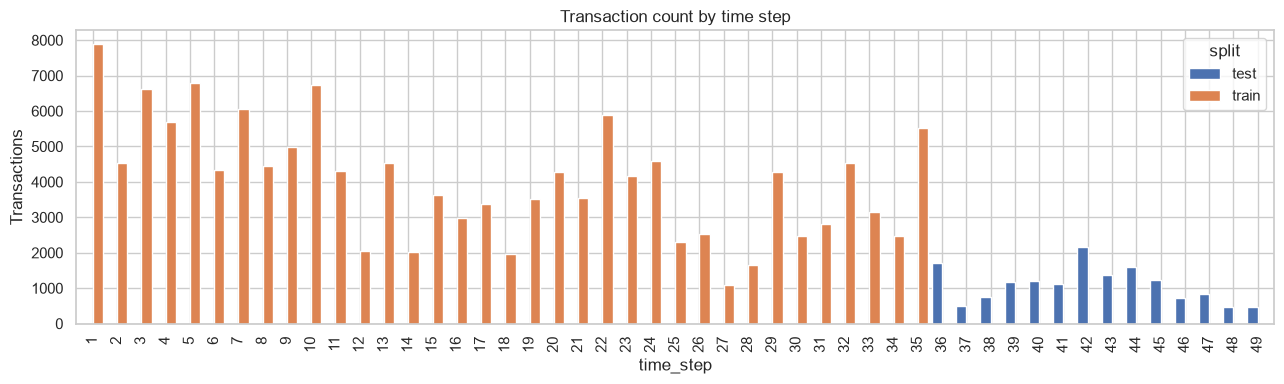

,transactions
label_clean,
unknown,110537
licit (0),27591
illicit (1),3644


Known-label illicit rate: 11.666% (31,235 labeled transactions)


,total,known,illicit,labeled_fraction,illicit_rate_among_labeled
time_step,,,,,
1,7880,2147,17.0,0.272462,0.007918
2,4544,1117,18.0,0.245819,0.016115
3,6621,1279,11.0,0.193173,0.0086
4,5693,1440,30.0,0.252942,0.020833
5,6803,1882,8.0,0.276643,0.004251
6,4328,485,5.0,0.112061,0.010309
7,6048,1203,102.0,0.198909,0.084788
8,4457,1165,67.0,0.261387,0.057511
9,4996,778,248.0,0.155725,0.318766


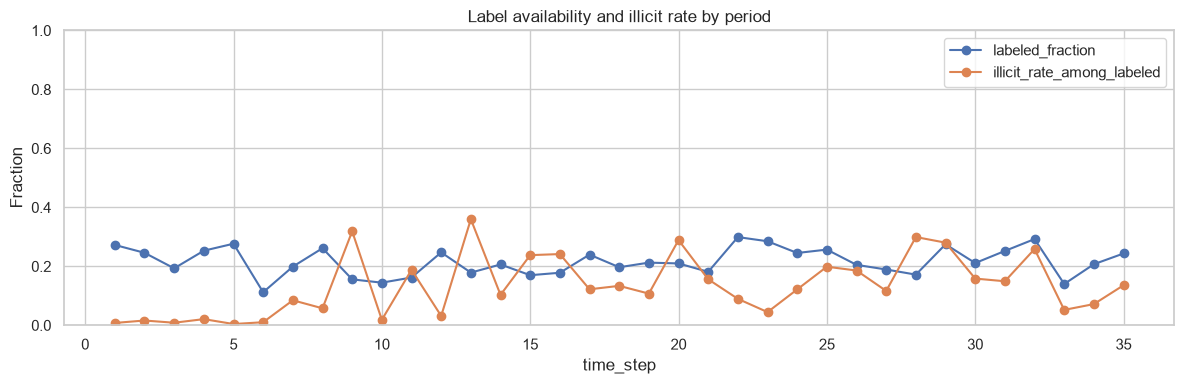

Rates describe labeled examples only; missing labels may be selected non-randomly.


In [8]:
parts = []
if train is not None:
    parts.append(train.assign(split="train"))
parts.append(test.assign(split="test"))
periods = pd.concat(parts, ignore_index=True).groupby(["time_step", "split"]).size().unstack(fill_value=0)
display(periods)
periods.plot(kind="bar", figsize=(13, 4), width=0.85)
plt.ylabel("Transactions"); plt.title("Transaction count by time step"); plt.tight_layout(); plt.show()
if train is None:
    print("Training label and time analyses are pending train.csv.")
else:
    counts = train.label_clean.map({0.0: "licit (0)", 1.0: "illicit (1)"}).fillna("unknown").value_counts()
    display(counts.rename("transactions").to_frame())
    known = train.dropna(subset=["label_clean"])
    print(f"Known-label illicit rate: {known.label_clean.mean():.3%} ({len(known):,} labeled transactions)")
    by_period = train.groupby("time_step").agg(
        total=("txId", "size"), known=("label_clean", "count"),
        illicit=("label_clean", "sum"))
    by_period["labeled_fraction"] = by_period.known / by_period.total
    by_period["illicit_rate_among_labeled"] = by_period.illicit / by_period.known.replace(0, np.nan)
    display(by_period)
    ax = by_period[["labeled_fraction", "illicit_rate_among_labeled"]].plot(figsize=(12, 4), marker="o")
    ax.set_ylabel("Fraction"); ax.set_ylim(0, 1); ax.set_title("Label availability and illicit rate by period")
    plt.tight_layout(); plt.show()
    print("Rates describe labeled examples only; missing labels may be selected non-randomly.")

## 3. Missingness, spread, and redundancy

Inspect all features in summary tables, then visualize a small set chosen from the training labels when available. The figures are exploratory; feature selection for a model must happen inside the training fold.

,missing_pct,unique,median,std,p01,p99
feat_1,0.0,135664,-0.168768,1.119660,-0.172976,2.804678
feat_2,0.0,16347,-0.158783,0.395017,-0.197610,0.663947
feat_3,0.0,8,-0.646376,0.961251,-1.201369,1.573595
feat_4,0.0,268,-0.121970,0.990140,-0.121970,1.678931
feat_5,0.0,221,-0.043875,1.113030,-0.063725,0.372976
feat_6,0.0,252,-0.113002,0.994618,-0.113002,1.564243
feat_7,0.0,102,-0.061584,0.956036,-0.061584,1.155601
feat_8,0.0,124461,-0.161930,1.129079,-0.163645,2.783580
feat_9,0.0,125772,-0.165824,1.120331,-0.169454,2.787773
feat_10,0.0,35262,-0.049707,0.894260,-0.049707,0.676641


Features with missing values: 0
Features with <= 1 distinct observed value: 0


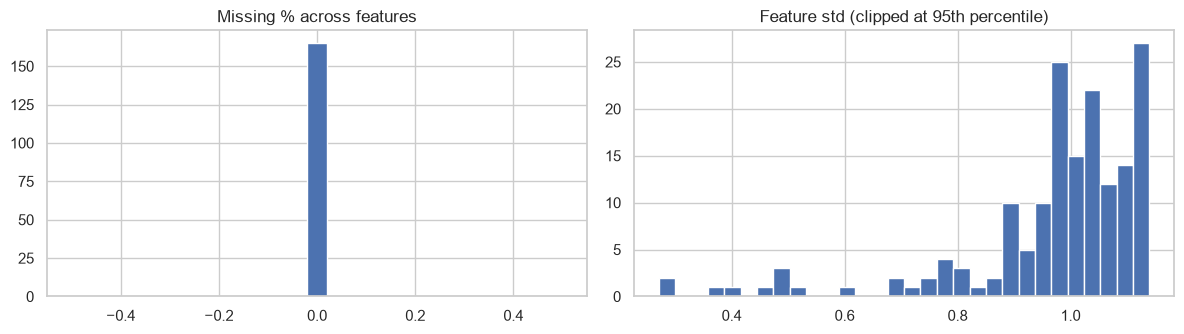

In [9]:
base = train if train is not None else test
X = base[feature_cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
feature_summary = pd.DataFrame({
    "missing_pct": X.isna().mean() * 100,
    "unique": X.nunique(dropna=True),
    "median": X.median(),
    "std": X.std(),
    "p01": X.quantile(.01), "p99": X.quantile(.99)
})
display(feature_summary.sort_values("missing_pct", ascending=False).head(20))
print("Features with missing values:", int((feature_summary.missing_pct > 0).sum()))
print("Features with <= 1 distinct observed value:", int((feature_summary.unique <= 1).sum()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
feature_summary.missing_pct.hist(bins=25, ax=axes[0]); axes[0].set_title("Missing % across features")
feature_summary["std"].clip(upper=feature_summary["std"].quantile(.95)).hist(bins=30, ax=axes[1]); axes[1].set_title("Feature std (clipped at 95th percentile)")
plt.tight_layout(); plt.show()

In [10]:
# Correlation is descriptive and computed on a capped, reproducible sample.
sampled = X.sample(n=min(5000, len(X)), random_state=42)
corr = sampled.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
display(pairs.rename("absolute correlation").head(15).to_frame())
print("Feature pairs with |Pearson r| >= 0.98:", int((pairs >= .98).sum()))

,,absolute correlation
feat_61,feat_67,1.000000
feat_58,feat_64,1.000000
feat_60,feat_66,1.000000
feat_59,feat_65,1.000000
feat_24,feat_30,1.000000
feat_25,feat_31,1.000000
feat_22,feat_28,1.000000
feat_23,feat_29,1.000000
feat_27,feat_33,1.000000
feat_26,feat_32,1.000000


Feature pairs with |Pearson r| >= 0.98: 80


## 4. Labeled class comparisons

Compare distributions for known labels only. The ranking below uses a simple standardized median gap to choose plots, not to claim causal or predictive value. The target's prevalence and feature relationships may shift over time.

,absolute median gap / pooled IQR
feat_154,2.666667
feat_142,2.543710
feat_76,1.625000
feat_130,1.238898
feat_6,1.000000
feat_163,1.000000
feat_160,1.000000
feat_112,1.000000
feat_64,0.785258
feat_58,0.780570


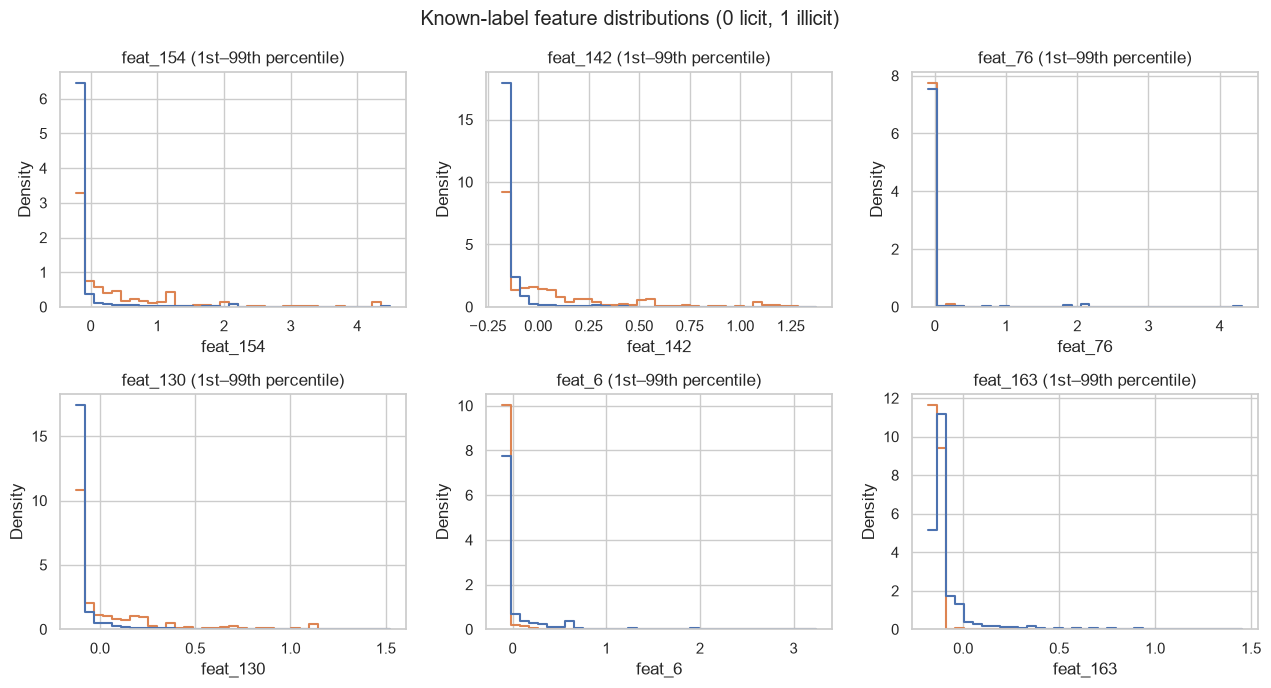

In [11]:
if train is None:
    print("Add train.csv to run class distribution comparisons.")
else:
    known = train.loc[train.label_clean.isin([0, 1])].copy()
    known[feature_cols] = known[feature_cols].apply(pd.to_numeric, errors="coerce")
    med = known.groupby("label_clean")[feature_cols].median()
    pooled_iqr = known[feature_cols].quantile(.75) - known[feature_cols].quantile(.25)
    gap = ((med.loc[1.0] - med.loc[0.0]).abs() / pooled_iqr.replace(0, np.nan)).sort_values(ascending=False)
    display(gap.rename("absolute median gap / pooled IQR").head(15).to_frame())
    selected = gap.dropna().head(6).index.tolist()
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for col, ax in zip(selected, axes.flat):
        lo, hi = known[col].quantile([.01, .99])
        view = known.loc[known[col].between(lo, hi), [col, "label_clean"]]
        sns.histplot(data=view, x=col, hue="label_clean", stat="density", common_norm=False,
                     element="step", fill=False, bins=35, ax=ax, legend=False)
        ax.set_title(col + " (1st–99th percentile)")
    for ax in axes.flat[len(selected):]: ax.axis("off")
    fig.suptitle("Known-label feature distributions (0 licit, 1 illicit)")
    plt.tight_layout(); plt.show()

## 5. Train → test feature shift

The test period is later in time. A large median shift relative to the training IQR is a prompt to inspect robustness; it is not proof of a useful feature or a label shift. This descriptive calculation includes all training rows because their features exist even when labels are unknown.

,absolute median shift / train IQR
feat_127,5.000000
feat_107,4.116625
feat_125,4.000000
feat_109,3.123159
feat_2,2.263000
feat_145,2.058713
feat_106,1.939567
feat_143,1.876097
feat_53,1.857678
feat_142,1.638367


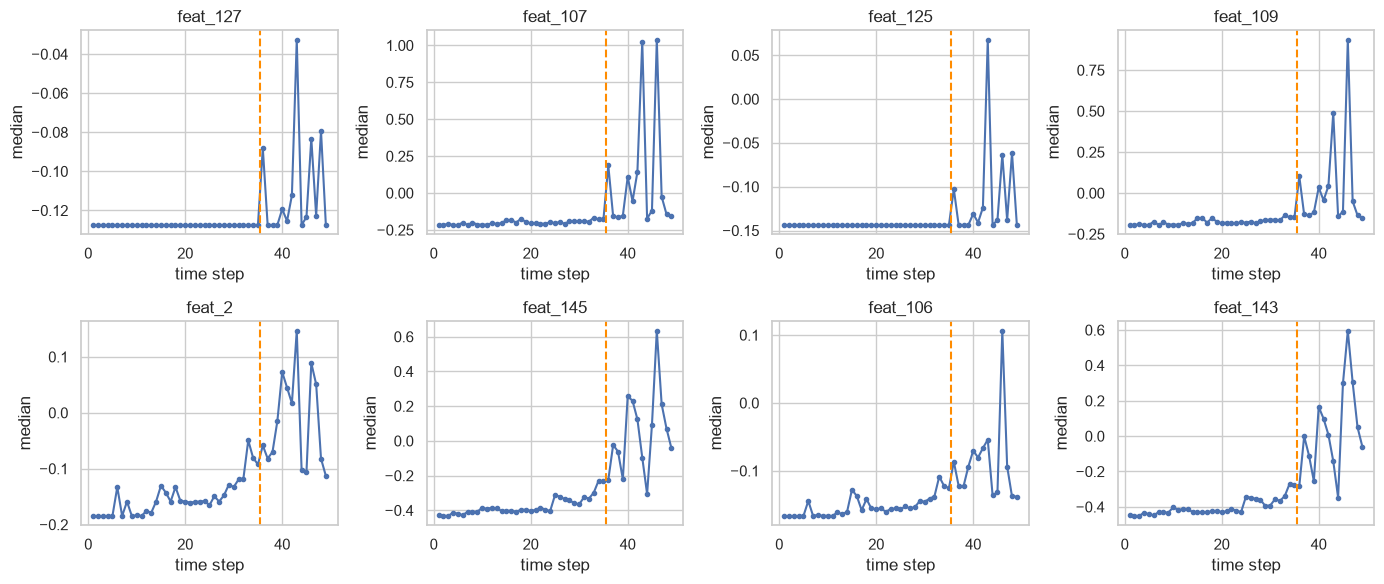

In [12]:
if train is None:
    print("Add train.csv to compare train and future test feature distributions.")
else:
    A = train[feature_cols].apply(pd.to_numeric, errors="coerce")
    B = test[feature_cols].apply(pd.to_numeric, errors="coerce")
    iqr = (A.quantile(.75) - A.quantile(.25)).replace(0, np.nan)
    shift = ((B.median() - A.median()).abs() / iqr).sort_values(ascending=False)
    display(shift.rename("absolute median shift / train IQR").head(20).to_frame())
    show = shift.dropna().head(8).index
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    for col, ax in zip(show, axes.flat):
        plot_df = pd.concat([train[["time_step", col]], test[["time_step", col]]])
        plot_df.groupby("time_step")[col].median().plot(ax=ax, marker=".")
        ax.axvline(train.time_step.max() + .5, color="darkorange", linestyle="--")
        ax.set_title(col); ax.set_xlabel("time step"); ax.set_ylabel("median")
    plt.tight_layout(); plt.show()

## 6. Directed graph structure

`txId1 → txId2` means an output of the source transaction is spent by the destination transaction. Degree measures distinct **observed connections**, not the exact number of Bitcoin inputs/outputs. The graph may contain additional unlabeled nodes outside either table. Time steps are coarse, so equal steps do not establish a within-step order.

Edges: 234355 duplicate directed pairs: 0 self-loops: 0
Unique graph nodes: 203769


,split,nodes,any observed edge %,mean in-degree,mean out-degree,max total degree
0,train,141772,100.0,1.151102,1.151102,473
1,test,15329,100.0,2.017744,1.224020,241


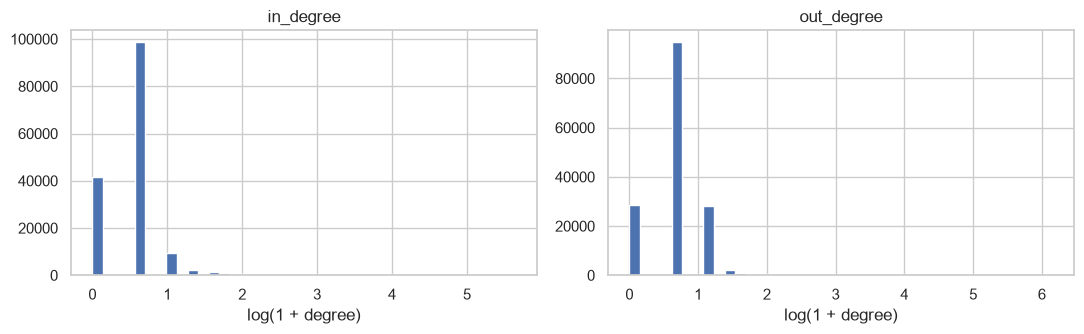

In [13]:
print("Edges:", len(edges), "duplicate directed pairs:", int(edges.duplicated().sum()),
      "self-loops:", int((edges.txId1 == edges.txId2).sum()))
all_nodes = pd.Index(pd.unique(edges[["txId1", "txId2"]].to_numpy().ravel()))
print("Unique graph nodes:", len(all_nodes))
in_degree = edges.groupby("txId2").size().rename("in_degree")
out_degree = edges.groupby("txId1").size().rename("out_degree")
nodes = pd.Index(pd.unique(pd.concat([test.txId, train.txId if train is not None else pd.Series(dtype="string")], ignore_index=True)))
degrees = pd.DataFrame(index=nodes).join(in_degree).join(out_degree).fillna(0).astype(int)
degrees["total_degree"] = degrees.in_degree + degrees.out_degree
coverage = []
for name, df in [("train", train), ("test", test)]:
    if df is None: continue
    d = degrees.reindex(df.txId)
    coverage.append({"split": name, "nodes": len(df), "any observed edge %": (d.total_degree.gt(0)).mean()*100,
                     "mean in-degree": d.in_degree.mean(), "mean out-degree": d.out_degree.mean(),
                     "max total degree": d.total_degree.max()})
display(pd.DataFrame(coverage))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for col, ax in zip(["in_degree", "out_degree"], axes):
    np.log1p(degrees[col]).hist(bins=40, ax=ax)
    ax.set_title(col); ax.set_xlabel("log(1 + degree)")
plt.tight_layout(); plt.show()

In [14]:
node_times = test[["txId", "time_step"]]
if train is not None:
    node_times = pd.concat([train[["txId", "time_step"]], node_times], ignore_index=True)
node_times = node_times.drop_duplicates("txId")
times = node_times.set_index("txId").time_step
edge_times = pd.DataFrame({"source_time": edges.txId1.map(times),
                           "destination_time": edges.txId2.map(times)})
observed = edge_times.dropna()
print(f"Edges with both endpoint time steps in available tables: {len(observed):,} / {len(edges):,}")
if len(observed):
    print("Same step:", int((observed.source_time == observed.destination_time).sum()))
    print("Source later than destination (investigate if any):", int((observed.source_time > observed.destination_time).sum()))
    display((observed.destination_time - observed.source_time).value_counts().sort_index().rename("edges").head(15).to_frame())
else:
    print("No edge has both endpoints in the currently available tables.")
if train is not None:
    labeled_degrees = train[["txId", "label_clean"]].join(degrees, on="txId")
    display(labeled_degrees.groupby("label_clean", dropna=False)[["in_degree", "out_degree"]].agg(["median", "mean"]))
    print("Keep label-based neighbor summaries within each training fold to avoid leakage.")

Edges with both endpoint time steps in available tables: 175,918 / 234,355
Same step: 175918
Source later than destination (investigate if any): 0


,edges
0.0,175918


in_degree           out_degree          
               median      mean     median      mean
label_clean                                         
0.0               1.0  1.830379        1.0  1.148382
1.0               1.0  1.254391        1.0  0.754665
<NA>              1.0  0.978143        1.0  1.164850

Keep label-based neighbor summaries within each training fold to avoid leakage.


## 7. EDA notes for the modelling notebook

Record findings after running with `train.csv`:

- **Labels:** fraction unknown, illicit rate among known labels, and whether either changes by time step.
- **Features:** missing or infinite values, extreme distributions, highly correlated groups, and train → test shifts.
- **Graph:** edge coverage, degree skew, time consistency, and whether graph features can be computed without using validation labels.
- **Validation:** reserve the latest *labeled* training time steps as a future-style holdout; fit preprocessing and feature selection on earlier training periods only. Keep unknown labels out of supervised metrics. Recompute any label-derived graph aggregates within each training fold.
- **Evaluation:** report ROC AUC on labeled holdout rows (the competition metric), alongside precision/recall or a precision–recall curve to understand false alerts under imbalance. Predict illicit probabilities for each `test.csv` `index` in the sample submission order.

The final competition model notebook has a separate required name based on your NUS student number; this `eda.ipynb` is for exploration.

# 7. Main Findings
| Finding from the notebook | Modelling implication |
|---|---|
| 141,772 training transactions, but only 31,235 have known labels; 3,644 of those are illicit (11.7%). | Train the first supervised baseline on known labels only. Do not treat the 110,537 unknowns as licit. |
| Training covers time steps 1–35; test covers 36–49, with no overlap. | Use a chronological holdout, such as training on 1–29 and validating on 30–35. A random split would answer a different question. |
| The illicit rate **among labeled rows** changes sharply by period. | Report ROC AUC by period as well as overall. That rate may also reflect how transactions were selected for labeling, so it is not necessarily the true illicit prevalence. |
| No missing, infinite, or constant feature columns were found. | You can begin with the 165 supplied features without a complex cleaning pipeline. |
| Several features are highly correlated, and some shift markedly in later periods. | Keep a simple all-feature baseline first. Compare later models on the same time holdout; do not drop features solely from the correlation table. |
| All train and test transactions have an observed graph edge; degree distributions differ between splits. | In-degree and out-degree are reasonable first graph features to test against the feature-only baseline. |